In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, confusion_matrix, classification_report,
                             roc_curve, auc, cohen_kappa_score, matthews_corrcoef)
from sklearn.preprocessing import label_binarize
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define Project Paths
BASE_DIR = "/content/drive/MyDrive/AI_Image_Project"
FEATURES_DIR = os.path.join(BASE_DIR, "features")
MODELS_DIR = os.path.join(BASE_DIR, "saved_models")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
CONF_DIR = os.path.join(RESULTS_DIR, "confusion_matrices")

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(CONF_DIR, exist_ok=True)

print("Loading optimized 500-feature matrices and strict split indices...")

# 3. Load Features, Labels, and Splits
X = np.load(os.path.join(FEATURES_DIR, "X_combined_500.npy"))
y = np.load(os.path.join(FEATURES_DIR, "y_labels_15k.npy"))

train_idx = np.load(os.path.join(FEATURES_DIR, "train_idx.npy"))
val_idx   = np.load(os.path.join(FEATURES_DIR, "val_idx.npy"))
test_idx  = np.load(os.path.join(FEATURES_DIR, "test_idx.npy"))

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val     = X[val_idx], y[val_idx]
X_test, y_test   = X[test_idx], y[test_idx]

CLASS_NAMES = ["Authentic", "Full AI", "Partial AI"]
print(f"Data ready. Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

Mounted at /content/drive
Loading optimized 500-feature matrices and strict split indices...
Data ready. Train: (12000, 500) | Val: (1500, 500) | Test: (1500, 500)


In [2]:
# Load pre-computed scaler parameters from Notebook 1
scaler_path = os.path.join(FEATURES_DIR, "scaler_params.npz")
if os.path.exists(scaler_path):
    scaler = np.load(scaler_path)
    mu, sigma = scaler["mu"], scaler["sigma"]
else:
    mu = np.mean(X_train, axis=0)
    sigma = np.std(X_train, axis=0)
    sigma[sigma < 1e-8] = 1.0  # Prevent division by zero

epsilon = 1e-8

# Apply Z-Score Normalization
X_train_norm = (X_train - mu) / (sigma + epsilon)
X_val_norm   = (X_val - mu) / (sigma + epsilon)
X_test_norm  = (X_test - mu) / (sigma + epsilon)

print(f"Normalization verified. Train Mean: {np.mean(X_train_norm):.4f}, Train Std: {np.std(X_train_norm):.4f}")

Normalization verified. Train Mean: -0.0000, Train Std: 1.0000


In [3]:
class ScratchMultinomialLogisticRegression:
    def __init__(self, C=1.0, learning_rate=0.1, epochs=200, batch_size=256, decay=0.001, random_state=42):
        self.C = float(C)
        self.lr = float(learning_rate)
        self.epochs = int(epochs)
        self.batch_size = int(batch_size)
        self.decay = float(decay)
        self.random_state = random_state
        self.weights = None
        self.bias = None
        self.train_loss_history = []
        self.val_loss_history = []

    def _softmax(self, z):
        z_shifted = z - np.max(z, axis=1, keepdims=True)
        exp_z = np.exp(np.clip(z_shifted, -50, 50))
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)

    def _compute_loss(self, X, y_one_hot, lambda_reg):
        n_samples = X.shape[0]
        z = np.dot(X, self.weights) + self.bias
        probs = self._softmax(z)

        ce_loss = -np.mean(np.sum(y_one_hot * np.log(probs + 1e-12), axis=1))
        l2_loss = (lambda_reg / (2 * n_samples)) * np.sum(self.weights ** 2)
        return ce_loss + l2_loss

    def fit(self, X, y, X_val=None, y_val=None, verbose=False):
        n_samples, n_features = X.shape
        self.classes_ = np.unique(y)
        n_classes = len(self.classes_)
        lambda_reg = 1.0 / max(self.C, 1e-12)

        rng = np.random.default_rng(self.random_state)
        self.weights = rng.normal(0.0, np.sqrt(2.0 / n_features), size=(n_features, n_classes))
        self.bias = np.zeros((1, n_classes))

        y_one_hot = np.zeros((n_samples, n_classes))
        y_one_hot[np.arange(n_samples), y] = 1.0

        if X_val is not None:
            y_val_one_hot = np.zeros((len(y_val), n_classes))
            y_val_one_hot[np.arange(len(y_val)), y_val] = 1.0

        step = 0
        for epoch in range(self.epochs):
            perm = rng.permutation(n_samples)
            X_shuffled = X[perm]
            y_shuffled = y_one_hot[perm]

            for start_idx in range(0, n_samples, self.batch_size):
                end_idx = min(start_idx + self.batch_size, n_samples)
                X_batch = X_shuffled[start_idx:end_idx]
                y_batch = y_shuffled[start_idx:end_idx]
                b_size = X_batch.shape[0]

                current_lr = self.lr / (1.0 + self.decay * step)
                step += 1

                z = np.dot(X_batch, self.weights) + self.bias
                probs = self._softmax(z)

                dz = probs - y_batch
                dw = (np.dot(X_batch.T, dz) / b_size) + (lambda_reg / n_samples) * self.weights
                db = np.sum(dz, axis=0, keepdims=True) / b_size

                self.weights -= current_lr * dw
                self.bias -= current_lr * db

            if verbose and (epoch % 20 == 0 or epoch == self.epochs - 1):
                train_loss = self._compute_loss(X, y_one_hot, lambda_reg)
                self.train_loss_history.append(train_loss)
                if X_val is not None:
                    val_loss = self._compute_loss(X_val, y_val_one_hot, lambda_reg)
                    self.val_loss_history.append(val_loss)

        return self

    def predict_proba(self, X):
        z = np.dot(X, self.weights) + self.bias
        return self._softmax(z)

    def predict(self, X):
        probs = self.predict_proba(X)
        return self.classes_[np.argmax(probs, axis=1)]

Starting Hyperparameter Tuning for C...
C=0.0001 | Train F1: 0.7765 | Val F1: 0.7554 | Time: 4.69s
C=0.001  | Train F1: 0.8166 | Val F1: 0.7915 | Time: 4.70s
C=0.01   | Train F1: 0.8380 | Val F1: 0.8048 | Time: 5.57s
C=0.1    | Train F1: 0.8442 | Val F1: 0.8077 | Time: 4.62s
C=1.0    | Train F1: 0.8456 | Val F1: 0.8090 | Time: 4.65s
C=10.0   | Train F1: 0.8455 | Val F1: 0.8084 | Time: 4.58s

Optimal C Selected: 1.0


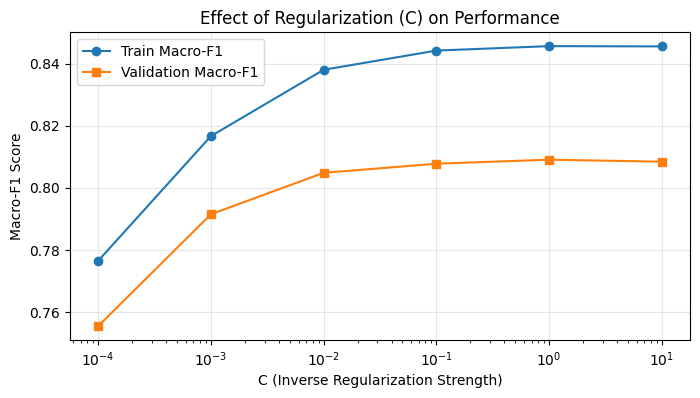

In [4]:
C_candidates = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0]
tuning_results = []

print("Starting Hyperparameter Tuning for C...")
for c_val in C_candidates:
    t0 = time.time()
    temp_model = ScratchMultinomialLogisticRegression(C=c_val, learning_rate=0.1, epochs=150, batch_size=256)
    temp_model.fit(X_train_norm, y_train)

    train_preds = temp_model.predict(X_train_norm)
    val_preds = temp_model.predict(X_val_norm)

    train_f1 = f1_score(y_train, train_preds, average='macro')
    val_f1 = f1_score(y_val, val_preds, average='macro')

    elapsed = time.time() - t0
    tuning_results.append({"C": c_val, "Train_F1": train_f1, "Val_F1": val_f1, "Time (s)": elapsed})
    print(f"C={c_val:<6} | Train F1: {train_f1:.4f} | Val F1: {val_f1:.4f} | Time: {elapsed:.2f}s")

df_tune = pd.DataFrame(tuning_results)
best_c = df_tune.sort_values(by="Val_F1", ascending=False).iloc[0]["C"]
print(f"\nOptimal C Selected: {best_c}")

# Plot Tuning Curves
plt.figure(figsize=(8, 4))
plt.plot(df_tune["C"], df_tune["Train_F1"], marker='o', label='Train Macro-F1')
plt.plot(df_tune["C"], df_tune["Val_F1"], marker='s', label='Validation Macro-F1')
plt.xscale('log')
plt.title("Effect of Regularization (C) on Performance")
plt.xlabel("C (Inverse Regularization Strength)")
plt.ylabel("Macro-F1 Score")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Training final Logistic Regression model with best C = 1.0...
Final training finished in 9.86 seconds.


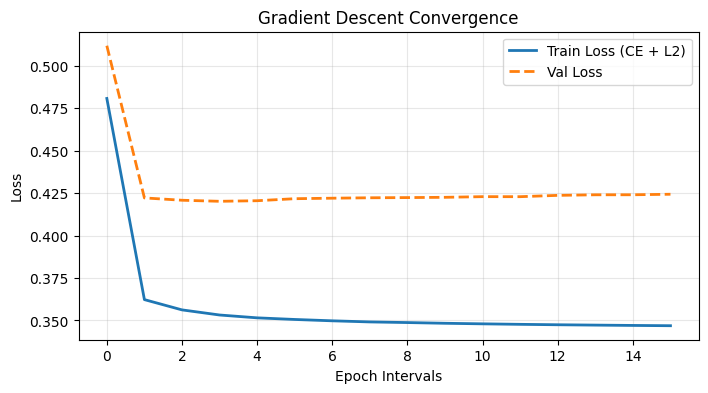

In [5]:
print(f"Training final Logistic Regression model with best C = {best_c}...")
final_model = ScratchMultinomialLogisticRegression(
    C=best_c, learning_rate=0.1, epochs=300, batch_size=256
)

start_t = time.time()
final_model.fit(X_train_norm, y_train, X_val=X_val_norm, y_val=y_val, verbose=True)
train_time = time.time() - start_t
print(f"Final training finished in {train_time:.2f} seconds.")

# Plot Convergence
plt.figure(figsize=(8, 4))
plt.plot(final_model.train_loss_history, label='Train Loss (CE + L2)', lw=2)
plt.plot(final_model.val_loss_history, label='Val Loss', lw=2, linestyle='--')
plt.title("Gradient Descent Convergence")
plt.xlabel("Epoch Intervals")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

FINAL TEST EVALUATION METRICS
Model               : Logistic Regression (Scratch)
Accuracy (%)        : 80.8
Macro F1            : 0.8077
Weighted F1         : 0.8077
ROC-AUC (OvR)       : 0.9304
Log Loss            : 0.4124
Cohen's Kappa       : 0.712
MCC                 : 0.7123
Train Time (s)      : 9.86

              precision    recall  f1-score   support

   Authentic       0.72      0.69      0.71       500
     Full AI       0.97      0.97      0.97       500
  Partial AI       0.73      0.76      0.74       500

    accuracy                           0.81      1500
   macro avg       0.81      0.81      0.81      1500
weighted avg       0.81      0.81      0.81      1500



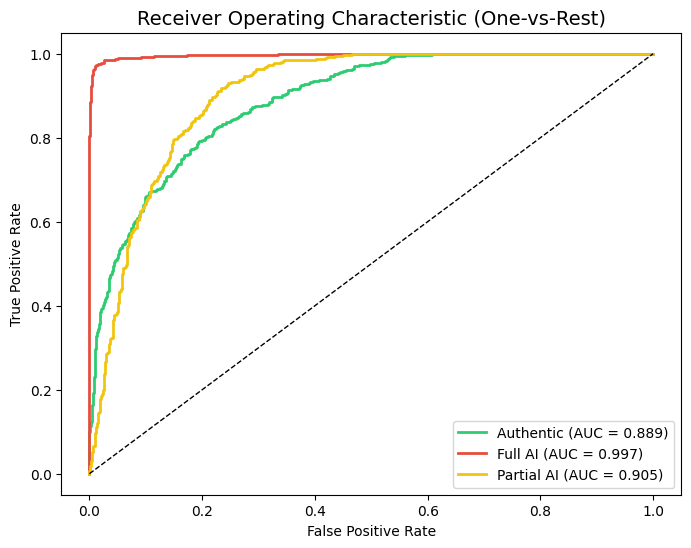

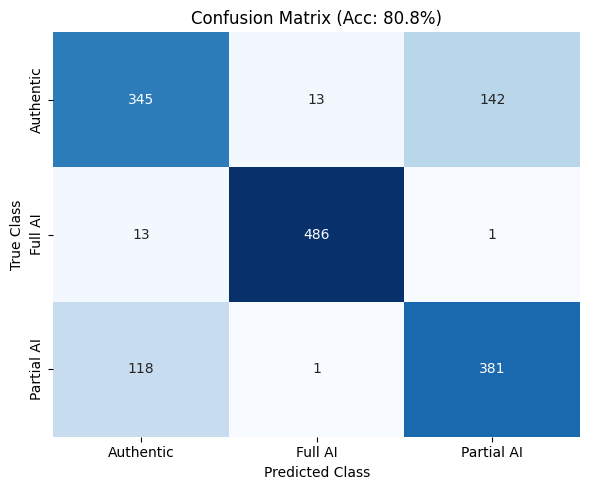


Model weights saved to: /content/drive/MyDrive/AI_Image_Project/saved_models/logreg_weights.npz
Metrics appended to: /content/drive/MyDrive/AI_Image_Project/results/model_comparison_15k.csv


In [6]:
# 1. Generate Predictions & Probabilities
y_test_pred = final_model.predict(X_test_norm)
y_test_prob = final_model.predict_proba(X_test_norm)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

# 2. Compute Advanced Metrics
metrics_dict = {
    "Model": "Logistic Regression (Scratch)",
    "Accuracy (%)": round(accuracy_score(y_test, y_test_pred) * 100, 2),
    "Macro F1": round(f1_score(y_test, y_test_pred, average='macro'), 4),
    "Weighted F1": round(f1_score(y_test, y_test_pred, average='weighted'), 4),
    "ROC-AUC (OvR)": round(roc_auc_score(y_test, y_test_prob, multi_class='ovr'), 4),
    "Log Loss": round(log_loss(y_test, y_test_prob), 4),
    "Cohen's Kappa": round(cohen_kappa_score(y_test, y_test_pred), 4),
    "MCC": round(matthews_corrcoef(y_test, y_test_pred), 4),
    "Train Time (s)": round(train_time, 2)
}

print("=" * 60)
print("FINAL TEST EVALUATION METRICS")
print("=" * 60)
for k, v in metrics_dict.items():
    print(f"{k:<20}: {v}")
print("\n" + classification_report(y_test, y_test_pred, target_names=CLASS_NAMES))

# 3. Plot ROC-AUC Curves
plt.figure(figsize=(8, 6))
colors = ['#2ecc71', '#e74c3c', '#f1c40f']
for i, color in enumerate(colors):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_test_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2, label=f'{CLASS_NAMES[i]} (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.title("Receiver Operating Characteristic (One-vs-Rest)", fontsize=14)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.savefig(os.path.join(CONF_DIR, "lr_roc_curve.png"), dpi=200)
plt.show()

# 4. Plot Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False)
plt.title(f"Confusion Matrix (Acc: {metrics_dict['Accuracy (%)']}%)")
plt.ylabel("True Class")
plt.xlabel("Predicted Class")
plt.tight_layout()
plt.savefig(os.path.join(CONF_DIR, "logreg_cm_15k.png"), dpi=200)
plt.show()

# 5. Save Model and Output Metrics
# Save learned weights to avoid retraining
model_save_path = os.path.join(MODELS_DIR, "logreg_weights.npz")
np.savez(model_save_path, W=final_model.weights, b=final_model.bias, best_c=best_c)

# Save probabilities for the ensemble notebook
np.save(os.path.join(MODELS_DIR, "logreg_val_probs.npy"), final_model.predict_proba(X_val_norm))
np.save(os.path.join(MODELS_DIR, "logreg_test_probs.npy"), y_test_prob)

# Save/Update CSV
csv_path = os.path.join(RESULTS_DIR, "model_comparison_15k.csv")
if os.path.exists(csv_path):
    df_results = pd.read_csv(csv_path)
    df_results = df_results[df_results["Model"] != metrics_dict["Model"]]
    df_results = pd.concat([df_results, pd.DataFrame([metrics_dict])], ignore_index=True)
else:
    df_results = pd.DataFrame([metrics_dict])
df_results.to_csv(csv_path, index=False)

print(f"\nModel weights saved to: {model_save_path}")
print(f"Metrics appended to: {csv_path}")

In [7]:
# 1. Compute PCA from scratch on the training set
cov_matrix = np.cov(X_train_norm, rowvar=False)
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# Sort eigenvectors by decreasing eigenvalues
sorted_idx = np.argsort(eigenvalues)[::-1]
eigenvectors_sorted = eigenvectors[:, sorted_idx]

# Select top components (e.g., explaining majority variance)
n_components = 100
pca_components = eigenvectors_sorted[:, :n_components]

# Transform datasets
X_train_pca = np.dot(X_train_norm, pca_components)
X_val_pca = np.dot(X_val_norm, pca_components)
X_test_pca = np.dot(X_test_norm, pca_components)

print(f"Original features: {X_train_norm.shape[1]} | PCA features: {X_train_pca.shape[1]}")

# 2. Train and evaluate on PCA-reduced features
print(f"Training Logistic Regression on PCA features (C={best_c})...")
pca_model = ScratchMultinomialLogisticRegression(
    C=best_c, learning_rate=0.1, epochs=300, batch_size=256
)

t0 = time.time()
pca_model.fit(X_train_pca, y_train)
pca_time = time.time() - t0

# Evaluate
pca_val_preds = pca_model.predict(X_val_pca)
pca_val_f1 = f1_score(y_val, pca_val_preds, average='macro')

print(f"PCA Validation Macro-F1: {pca_val_f1:.4f} | Training Time: {pca_time:.2f}s")

Original features: 500 | PCA features: 100
Training Logistic Regression on PCA features (C=1.0)...
PCA Validation Macro-F1: 0.7504 | Training Time: 5.55s


Starting Learning Curve Evaluation...
Data:  10% | Samples:  1200 | Val F1: 0.1667 | Time: 0.93s
Data:  25% | Samples:  3000 | Val F1: 0.1667 | Time: 1.99s
Data:  50% | Samples:  6000 | Val F1: 0.5342 | Time: 3.90s
Data: 100% | Samples: 12000 | Val F1: 0.8105 | Time: 9.15s


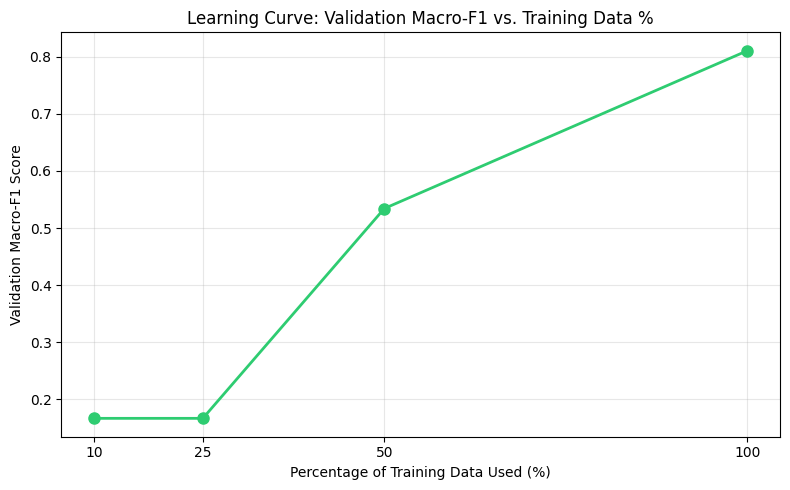

In [8]:
fractions = [0.10, 0.25, 0.50, 1.0]
val_f1_scores = []
train_times = []

print("Starting Learning Curve Evaluation...")

for f in fractions:
    n_samples = int(len(X_train_norm) * f)
    X_subset = X_train_norm[:n_samples]
    y_subset = y_train[:n_samples]

    # Initialize and train
    lc_model = ScratchMultinomialLogisticRegression(
        C=best_c, learning_rate=0.1, epochs=300, batch_size=256
    )

    t0 = time.time()
    lc_model.fit(X_subset, y_subset)
    elapsed = time.time() - t0

    # Evaluate on full validation set
    val_preds = lc_model.predict(X_val_norm)
    val_f1 = f1_score(y_val, val_preds, average='macro')

    val_f1_scores.append(val_f1)
    train_times.append(elapsed)

    print(f"Data: {int(f*100):>3}% | Samples: {n_samples:>5} | Val F1: {val_f1:.4f} | Time: {elapsed:.2f}s")

# Plot Learning Curve
plt.figure(figsize=(8, 5))
plt.plot([int(f*100) for f in fractions], val_f1_scores, marker='o', color='#2ecc71', lw=2, markersize=8)
plt.title("Learning Curve: Validation Macro-F1 vs. Training Data %")
plt.xlabel("Percentage of Training Data Used (%)")
plt.ylabel("Validation Macro-F1 Score")
plt.xticks([10, 25, 50, 100])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "lr_learning_curve.png"), dpi=200)
plt.show()